# AAL Australia – Apparel Sales Analysis
## Q4 2020 | Applied Data Science with Python – Course-End Project

---

**Objective:**  
Analyse AAL's Q4 2020 apparel-sales data on a state-by-state basis.  
Deliver actionable insights to support data-driven investment decisions for the upcoming year.

**Steps covered in this notebook:**
1. Environment setup & data loading
2. Data wrangling (missing-value inspection, normalisation, GroupBy insights)
3. Data analysis (descriptive statistics, weekly/monthly/quarterly aggregations)
4. Data visualisation (state-wise, group-wise, time-of-day, temporal dashboards)

---
## 1. Environment Setup & Data Loading

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
%matplotlib inline



Libraries loaded successfully.


In [2]:
# ── Load dataset ──────────────────────────────────────────────────────────────
df_raw = pd.read_csv('AusApparalSales4thQrt2020.csv')

print(f'Shape: {df_raw.shape}')
df_raw.head(10)

Shape: (7560, 6)


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500
5,1-Oct-2020,Afternoon,WA,Men,10,25000
6,1-Oct-2020,Afternoon,WA,Women,3,7500
7,1-Oct-2020,Afternoon,WA,Seniors,11,27500
8,1-Oct-2020,Evening,WA,Kids,15,37500
9,1-Oct-2020,Evening,WA,Men,15,37500


---
## 2. Data Wrangling

### 2.1 Initial Inspection

In [3]:
# Basic structural info
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    7560 non-null   object
 1   Time    7560 non-null   object
 2   State   7560 non-null   object
 3   Group   7560 non-null   object
 4   Unit    7560 non-null   int64 
 5   Sales   7560 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 354.5+ KB


In [4]:
# Preview dtypes and sample values
df_raw.dtypes

Date     object
Time     object
State    object
Group    object
Unit      int64
Sales     int64
dtype: object

### 2.2 Missing-Value Analysis

We use `isna()` / `notna()` as required by the project specification.

In [5]:
# Count of NaN per column
missing = df_raw.isna().sum()
print('Missing values per column:')
print(missing)
print(f'\nTotal missing cells: {missing.sum()}')

Missing values per column:
Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

Total missing cells: 0


In [6]:
# Proportion of non-null values
print('Non-null proportions:')
print(df_raw.notna().mean().round(4))

Non-null proportions:
Date    1.00
Time    1.00
State   1.00
Group   1.00
Unit    1.00
Sales   1.00
dtype: float64


**Recommendation – treating missing / incorrect data:**

| Scenario | Recommended treatment |
|---|---|
| Numeric columns (`Unit`, `Sales`) with < 5 % missing | Fill with **column median** (robust to outliers) |
| Categorical columns (`State`, `Group`, `Time`) with any missing | Fill with **mode** (most-frequent category) |
| Rows where > 50 % of fields are missing | **Drop** the row entirely |

Dropping rows is preferred only as a last resort because the dataset is transaction-level; imputation preserves temporal and group-level distributions.

In [7]:
# Work on a copy so we preserve the raw data
df = df_raw.copy()

# Strip leading/trailing whitespace from string columns
str_cols = df.select_dtypes('object').columns
df[str_cols] = df[str_cols].apply(lambda s: s.str.strip())

# Fill numeric NaNs with column median
for col in ['Unit', 'Sales']:
    if df[col].isna().any():
        df[col].fillna(df[col].median(), inplace=True)

# Fill categorical NaNs with mode
for col in ['State', 'Group', 'Time']:
    if df[col].isna().any():
        df[col].fillna(df[col].mode()[0], inplace=True)

# Drop any remaining fully-empty rows
df.dropna(how='all', inplace=True)

print(f'Clean shape: {df.shape}')
print('Remaining NaNs:', df.isna().sum().sum())

Clean shape: (7560, 6)
Remaining NaNs: 0


### 2.3 Type Conversion & Feature Engineering

In [8]:
# Parse dates
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Ensure numerics are correct types
df['Unit']  = pd.to_numeric(df['Unit'],  errors='coerce')
df['Sales'] = pd.to_numeric(df['Sales'], errors='coerce')

# Derived time features
df['Week']    = df['Date'].dt.isocalendar().week.astype(int)
df['Month']   = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%B')

# Ordered categories for consistent plotting
group_order  = ['Kids', 'Women', 'Men', 'Seniors']
time_order   = ['Morning', 'Afternoon', 'Evening', 'Night']
month_order  = ['October', 'November', 'December']

df['Group']      = pd.Categorical(df['Group'],      categories=group_order,  ordered=True)
df['Time']       = pd.Categorical(df['Time'],        categories=time_order,   ordered=True)
df['Month_Name'] = pd.Categorical(df['Month_Name'], categories=month_order,  ordered=True)

print('Sample after feature engineering:')
df.head()

Sample after feature engineering:


,Date,Time,State,Group,Unit,Sales,Week,Month,Month_Name
0,2020-10-01,Morning,WA,Kids,8,20000,40,10,October
1,2020-10-01,Morning,WA,Men,8,20000,40,10,October
2,2020-10-01,Morning,WA,Women,4,10000,40,10,October
3,2020-10-01,Morning,WA,Seniors,15,37500,40,10,October
4,2020-10-01,Afternoon,WA,Kids,3,7500,40,10,October


### 2.4 Normalisation

**Choice: Min-Max Normalisation (preferred)**

Min-Max normalisation scales every value to the **[0, 1]** range:
$$x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

**Why Min-Max over Standardisation (Z-score)?**

| Criterion | Min-Max | Z-score Standardisation |
|---|---|---|
| Sales figures are non-negative and bounded | Preserves this property | Can produce negative values |
| Outlier sensitivity | Moderate | More robust |
| Interpretability for business users | 0–100 % scale intuitive | Less intuitive |
| Requirement in problem statement |  Explicitly preferred | — |

Normalised columns are created alongside originals for comparative analysis.

In [9]:
def min_max_normalise(series: pd.Series) -> pd.Series:
    """Apply Min-Max normalisation to a numeric Series."""
    return (series - series.min()) / (series.max() - series.min())

df['Unit_Norm']  = min_max_normalise(df['Unit'])
df['Sales_Norm'] = min_max_normalise(df['Sales'])

print('Normalised columns added. Summary:')
df[['Unit', 'Unit_Norm', 'Sales', 'Sales_Norm']].describe().round(4)

Normalised columns added. Summary:


,Unit,Unit_Norm,Sales,Sales_Norm
count,"7,560.00","7,560.00","7,560.00","7,560.00"
mean,18.01,0.25,"45,013.56",0.25
std,12.90,0.20,"32,253.51",0.20
min,2.00,0.00,"5,000.00",0.00
25%,8.00,0.10,"20,000.00",0.10
50%,14.00,0.19,"35,000.00",0.19
75%,26.00,0.38,"65,000.00",0.38
max,65.00,1.00,"162,500.00",1.00


### 2.5 GroupBy Insights

**When to use GroupBy for chunking vs. merging:**

- **Chunking (split-apply-combine):** Use `groupby(...).agg()` to compute summary statistics per group (e.g., total sales per state). Best when the goal is aggregation or transformation within each segment.
- **Merging (pivot-style joins):** Use `groupby` combined with `unstack()` or `pivot_table()` when you need to compare groups side-by-side in a matrix format (e.g., state × group sales grid).

**Recommendation:** For this project we primarily use **chunking** (state-level, group-level, time-level aggregations) since the goal is to rank and compare segments independently before drawing cross-cutting conclusions.

In [10]:
# State-level aggregation (chunking)
state_sales = df.groupby('State')['Sales'].sum().sort_values(ascending=False)
print('Total Sales by State:')
print(state_sales.to_string())

Total Sales by State:
State
VIC    105565000
NSW     74970000
SA      58857500
QLD     33417500
TAS     22760000
NT      22580000
WA      22152500


In [11]:
# State × Group matrix (merging / pivot-style)
state_group_pivot = df.pivot_table(
    values='Sales', index='State', columns='Group', aggfunc='sum', fill_value=0
)
print('State × Group Total Sales:')
state_group_pivot

State × Group Total Sales:


/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/2971780463.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  state_group_pivot = df.pivot_table(


Group,Kids,Women,Men,Seniors
State,,,,
NSW,18587500,19172500,19022500,18187500
NT,5700000,5652500,5762500,5465000
QLD,8510000,8325000,8392500,8190000
SA,14515000,14970000,14655000,14717500
TAS,5775000,5577500,5757500,5650000
VIC,26360000,26482500,26407500,26315000
WA,5625000,5262500,5752500,5512500


---
## 3. Data Analysis

### 3.1 Descriptive Statistics – Sales & Unit Columns

In [12]:
for col in ['Sales', 'Unit']:
    print(f'\n── {col} ─────────────────────────────')
    print(f'  Mean      : {df[col].mean():>12,.2f}')
    print(f'  Median    : {df[col].median():>12,.2f}')
    print(f'  Mode      : {df[col].mode()[0]:>12,.2f}')
    print(f'  Std Dev   : {df[col].std():>12,.2f}')
    print(f'  Min       : {df[col].min():>12,.2f}')
    print(f'  Max       : {df[col].max():>12,.2f}')
    print(f'  Skewness  : {df[col].skew():>12,.4f}')
    print(f'  Kurtosis  : {df[col].kurt():>12,.4f}')


── Sales ─────────────────────────────
  Mean      :    45,013.56
  Median    :    35,000.00
  Mode      :    22,500.00
  Std Dev   :    32,253.51
  Min       :     5,000.00
  Max       :   162,500.00
  Skewness  :       1.0856
  Kurtosis  :       0.6614

── Unit ─────────────────────────────
  Mean      :        18.01
  Median    :        14.00
  Mode      :         9.00
  Std Dev   :        12.90
  Min       :         2.00
  Max       :        65.00
  Skewness  :       1.0856
  Kurtosis  :       0.6614


In [13]:
# Pandas describe for a compact view
df[['Sales', 'Unit']].describe().round(2)

,Sales,Unit
count,"7,560.00","7,560.00"
mean,"45,013.56",18.01
std,"32,253.51",12.90
min,"5,000.00",2.00
25%,"20,000.00",8.00
50%,"35,000.00",14.00
75%,"65,000.00",26.00
max,"162,500.00",65.00


### 3.2 Highest and Lowest Sales Groups

In [14]:
group_sales = df.groupby('Group', observed=True)['Sales'].sum().sort_values(ascending=False)
print('Sales by Group:')
print(group_sales.to_string())
print(f'\nHighest sales group : {group_sales.idxmax()}  (${group_sales.max():,.0f})')
print(f'Lowest  sales group : {group_sales.idxmin()}  (${group_sales.min():,.0f})')

Sales by Group:
Group
Men        85750000
Women      85442500
Kids       85072500
Seniors    84037500

Highest sales group : Men  ($85,750,000)
Lowest  sales group : Seniors  ($84,037,500)


In [15]:
state_sales_full = df.groupby('State')['Sales'].sum().sort_values(ascending=False)
print('Sales by State:')
print(state_sales_full.to_string())
print(f'\nHighest revenue state: {state_sales_full.idxmax()}  (${state_sales_full.max():,.0f})')
print(f'Lowest  revenue state: {state_sales_full.idxmin()}  (${state_sales_full.min():,.0f})')

Sales by State:
State
VIC    105565000
NSW     74970000
SA      58857500
QLD     33417500
TAS     22760000
NT      22580000
WA      22152500

Highest revenue state: VIC  ($105,565,000)
Lowest  revenue state: WA  ($22,152,500)


### 3.3 Weekly Report

In [16]:
weekly = df.groupby('Week')[['Sales', 'Unit']].agg(['sum', 'mean']).round(2)
weekly.columns = ['Total_Sales', 'Avg_Sales', 'Total_Units', 'Avg_Units']
weekly.index.name = 'ISO Week'
print('Weekly Aggregation:')
weekly

Weekly Aggregation:


,Total_Sales,Avg_Sales,Total_Units,Avg_Units
ISO Week,,,,
40,15045000,"44,776.79",6018,17.91
41,27002500,"45,922.62",10801,18.37
42,26640000,"45,306.12",10656,18.12
43,26815000,"45,603.74",10726,18.24
44,21807500,"43,268.85",8723,17.31
45,20865000,"35,484.69",8346,14.19
46,21172500,"36,007.65",8469,14.40
47,21112500,"35,905.61",8445,14.36
48,21477500,"36,526.36",8591,14.61


### 3.4 Monthly Report

In [17]:
monthly = df.groupby('Month_Name', observed=True)[['Sales', 'Unit']].agg(['sum', 'mean']).round(2)
monthly.columns = ['Total_Sales', 'Avg_Sales', 'Total_Units', 'Avg_Units']
monthly.index.name = 'Month'
print('Monthly Aggregation:')
monthly

Monthly Aggregation:


,Total_Sales,Avg_Sales,Total_Units,Avg_Units
Month,,,,
October,114290000,"45,353.17",45716,18.14
November,90682500,"35,985.12",36273,14.39
December,135330000,"53,702.38",54132,21.48


### 3.5 Quarterly Report (Q4 2020 Summary)

In [18]:
quarterly = {
    'Total Sales (AUD)' : df['Sales'].sum(),
    'Total Units Sold'  : df['Unit'].sum(),
    'Avg Daily Sales'   : df.groupby('Date')['Sales'].sum().mean(),
    'Peak Day Sales'    : df.groupby('Date')['Sales'].sum().max(),
    'Trough Day Sales'  : df.groupby('Date')['Sales'].sum().min(),
    'Unique States'     : df['State'].nunique(),
    'Transactions'      : len(df),
}
print('Q4 2020 – Quarterly Summary')
print('-' * 38)
for k, v in quarterly.items():
    if isinstance(v, float):
        print(f'  {k:<22}: {v:>14,.2f}')
    else:
        print(f'  {k:<22}: {v:>14,}')

Q4 2020 – Quarterly Summary
--------------------------------------
  Total Sales (AUD)     :    340,302,500
  Total Units Sold      :        136,121
  Avg Daily Sales       :   3,781,138.89
  Peak Day Sales        :      4,765,000
  Trough Day Sales      :      2,725,000
  Unique States         :              7
  Transactions          :          7,560


---
## 4. Data Visualisation

**Visualisation library choice: Seaborn + Matplotlib**

Seaborn is preferred because:
- Built on Matplotlib; supports all standard chart types.
- Native integration with Pandas DataFrames.
- Statistical overlays (KDE, CI bands, regression lines) are one-liners.
- Publication-quality themes with minimal boilerplate.

Matplotlib is used directly where fine-grained layout control is needed (subplots, axis formatting, annotations).

### 4.1 Box Plots – Descriptive Statistics (Sales & Units)

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/1036037212.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Group', y='Sales', order=group_order,
/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/1036037212.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Group', y='Unit', order=group_order,


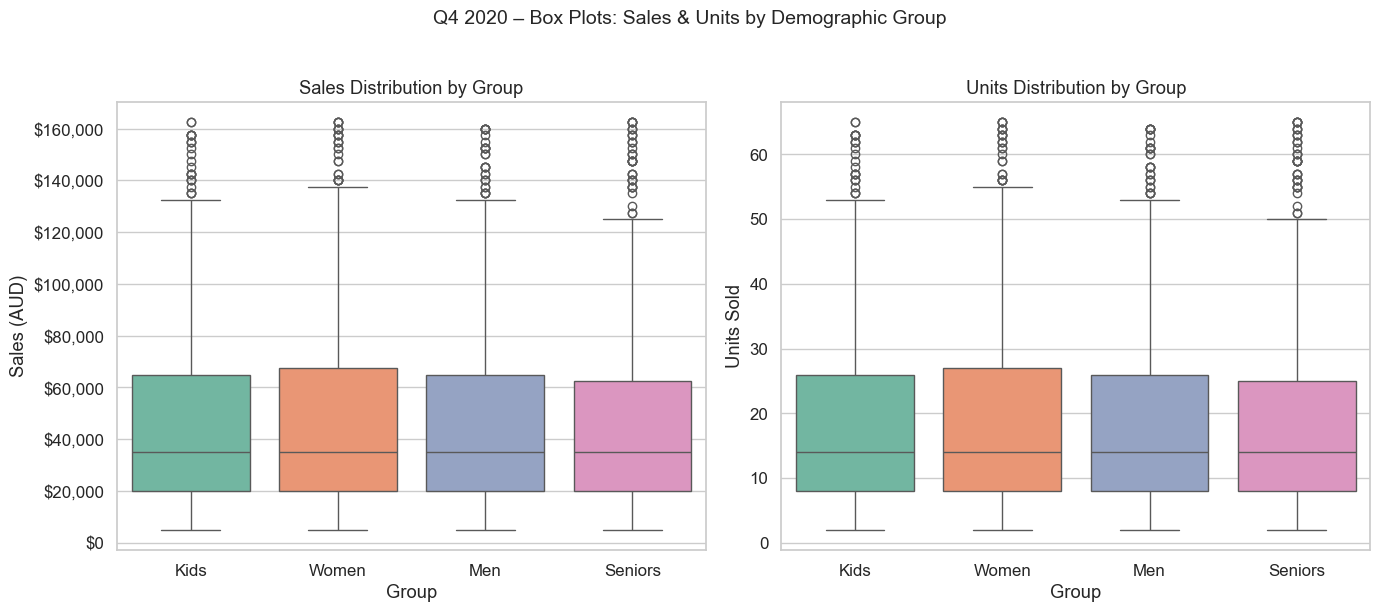

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=df, x='Group', y='Sales', order=group_order,
            palette='Set2', ax=axes[0])
axes[0].set_title('Sales Distribution by Group')
axes[0].set_xlabel('Group')
axes[0].set_ylabel('Sales (AUD)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

sns.boxplot(data=df, x='Group', y='Unit', order=group_order,
            palette='Set2', ax=axes[1])
axes[1].set_title('Units Distribution by Group')
axes[1].set_xlabel('Group')
axes[1].set_ylabel('Units Sold')

plt.suptitle('Q4 2020 – Box Plots: Sales & Units by Demographic Group', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('fig_boxplot_group.png', dpi=150, bbox_inches='tight')
plt.show()

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/3163203496.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='State', y='Sales', palette='Paired', ax=axes[0])
/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/3163203496.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='State', y='Unit', palette='Paired', ax=axes[1])


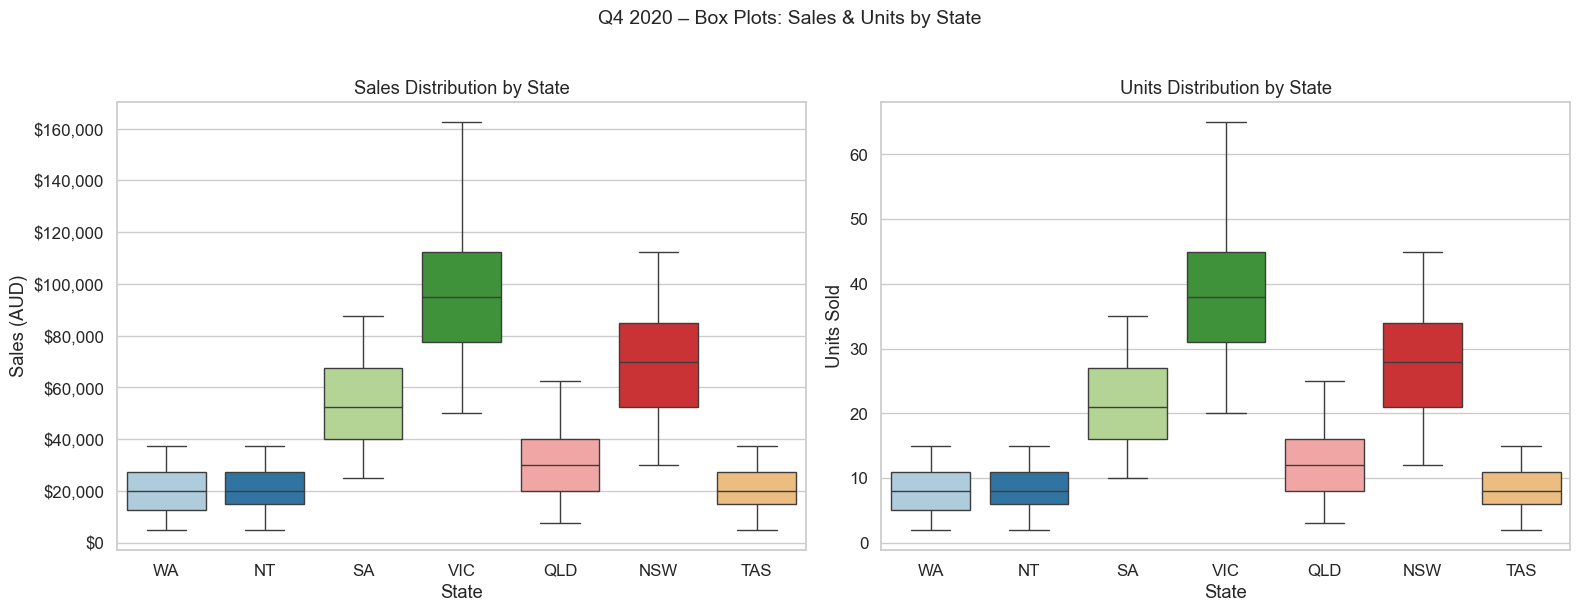

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df, x='State', y='Sales', palette='Paired', ax=axes[0])
axes[0].set_title('Sales Distribution by State')
axes[0].set_xlabel('State')
axes[0].set_ylabel('Sales (AUD)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

sns.boxplot(data=df, x='State', y='Unit', palette='Paired', ax=axes[1])
axes[1].set_title('Units Distribution by State')
axes[1].set_xlabel('State')
axes[1].set_ylabel('Units Sold')

plt.suptitle('Q4 2020 – Box Plots: Sales & Units by State', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('fig_boxplot_state.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2 Distribution Plots (Seaborn KDE)

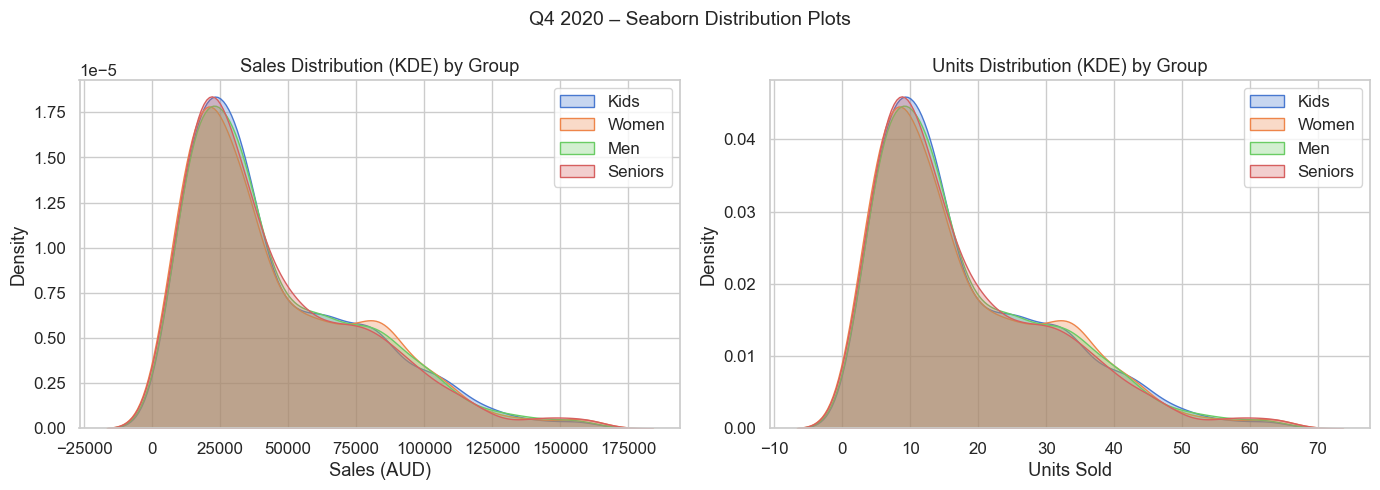

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for grp in group_order:
    subset = df[df['Group'] == grp]
    sns.kdeplot(subset['Sales'], ax=axes[0], label=grp, fill=True, alpha=0.3)
axes[0].set_title('Sales Distribution (KDE) by Group')
axes[0].set_xlabel('Sales (AUD)')
axes[0].legend()

for grp in group_order:
    subset = df[df['Group'] == grp]
    sns.kdeplot(subset['Unit'], ax=axes[1], label=grp, fill=True, alpha=0.3)
axes[1].set_title('Units Distribution (KDE) by Group')
axes[1].set_xlabel('Units Sold')
axes[1].legend()

plt.suptitle('Q4 2020 – Seaborn Distribution Plots', fontsize=14)
plt.tight_layout()
plt.savefig('fig_kde_group.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3 State-Wise Sales Analysis by Demographic Group

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/3051971320.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x='State', y='Sales', palette='Blues_d', ax=axes[i])
/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/3051971320.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x='State', y='Sales', palette='Blues_d', ax=axes[i])
/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/3051971320.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x='State', y='Sales', pa

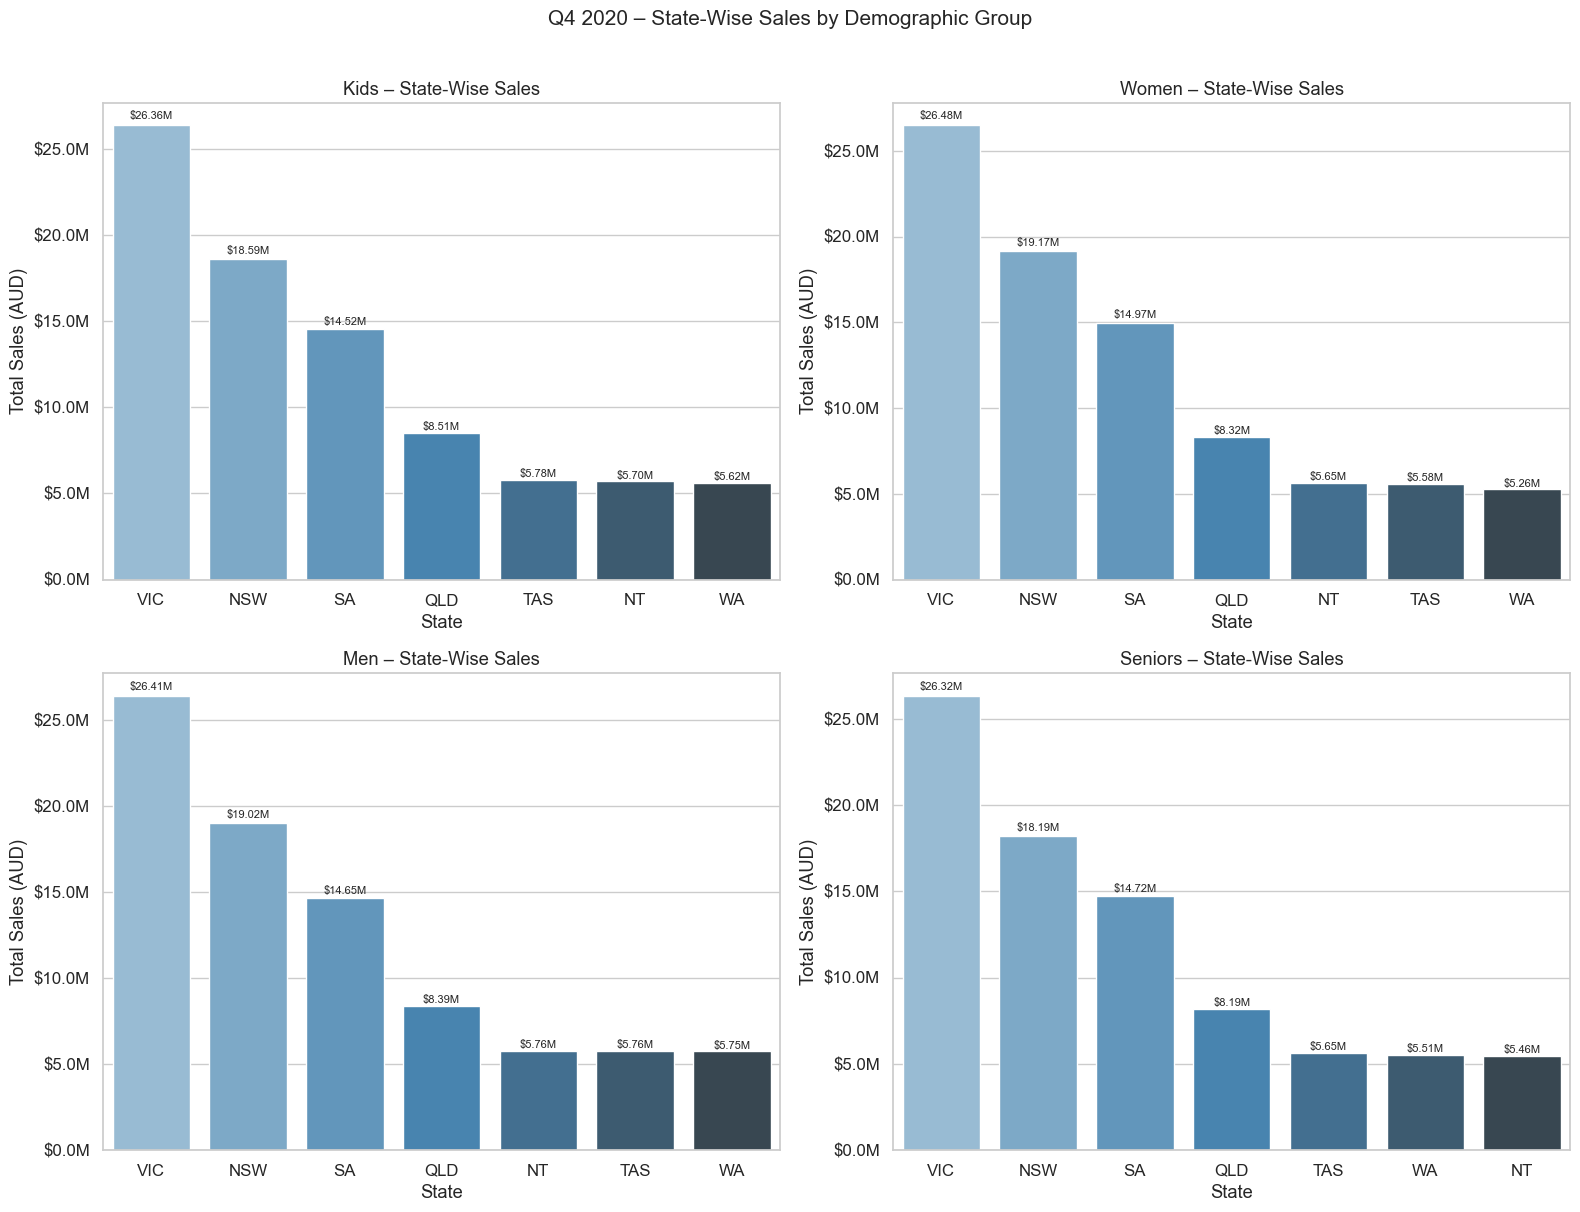

In [22]:
state_group = df.groupby(['State', 'Group'], observed=True)['Sales'].sum().reset_index()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, grp in enumerate(group_order):
    data = state_group[state_group['Group'] == grp].sort_values('Sales', ascending=False)
    sns.barplot(data=data, x='State', y='Sales', palette='Blues_d', ax=axes[i])
    axes[i].set_title(f'{grp} – State-Wise Sales')
    axes[i].set_xlabel('State')
    axes[i].set_ylabel('Total Sales (AUD)')
    axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
    for bar in axes[i].patches:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, h + h*0.01,
                     f'${h/1e6:.2f}M', ha='center', va='bottom', fontsize=8)

plt.suptitle('Q4 2020 – State-Wise Sales by Demographic Group', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig('fig_state_by_group.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.4 Group-Wise Sales Analysis Across States

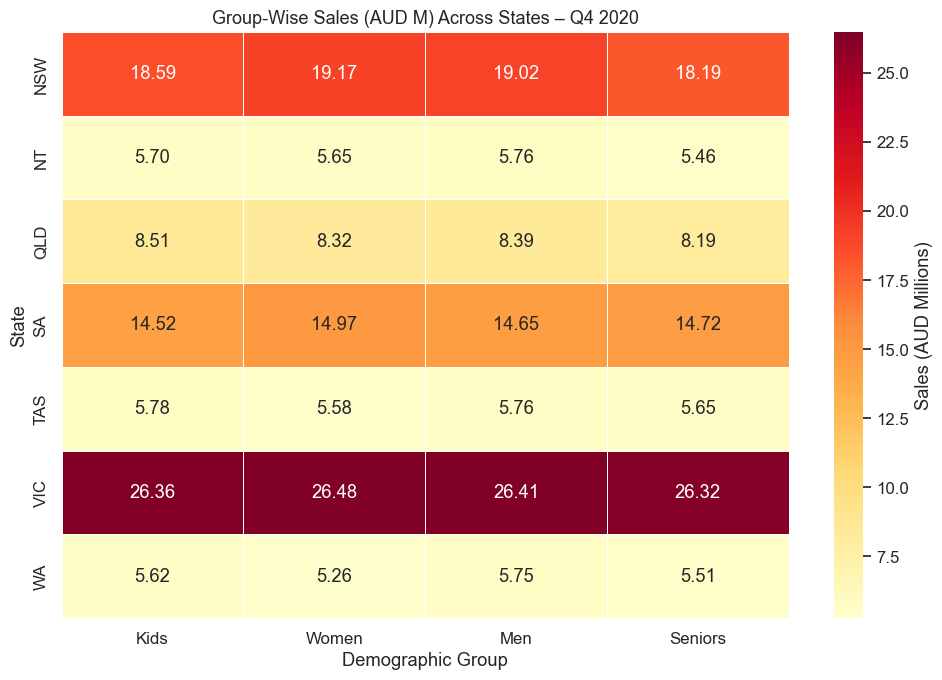

In [23]:
pivot_heatmap = df.pivot_table(
    values='Sales', index='State', columns='Group', aggfunc='sum', observed=True
)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    pivot_heatmap / 1e6,
    annot=True, fmt='.2f', cmap='YlOrRd',
    linewidths=0.5, ax=ax,
    cbar_kws={'label': 'Sales (AUD Millions)'}
)
ax.set_title('Group-Wise Sales (AUD M) Across States – Q4 2020', fontsize=13)
ax.set_xlabel('Demographic Group')
ax.set_ylabel('State')
plt.tight_layout()
plt.savefig('fig_heatmap_state_group.png', dpi=150, bbox_inches='tight')
plt.show()

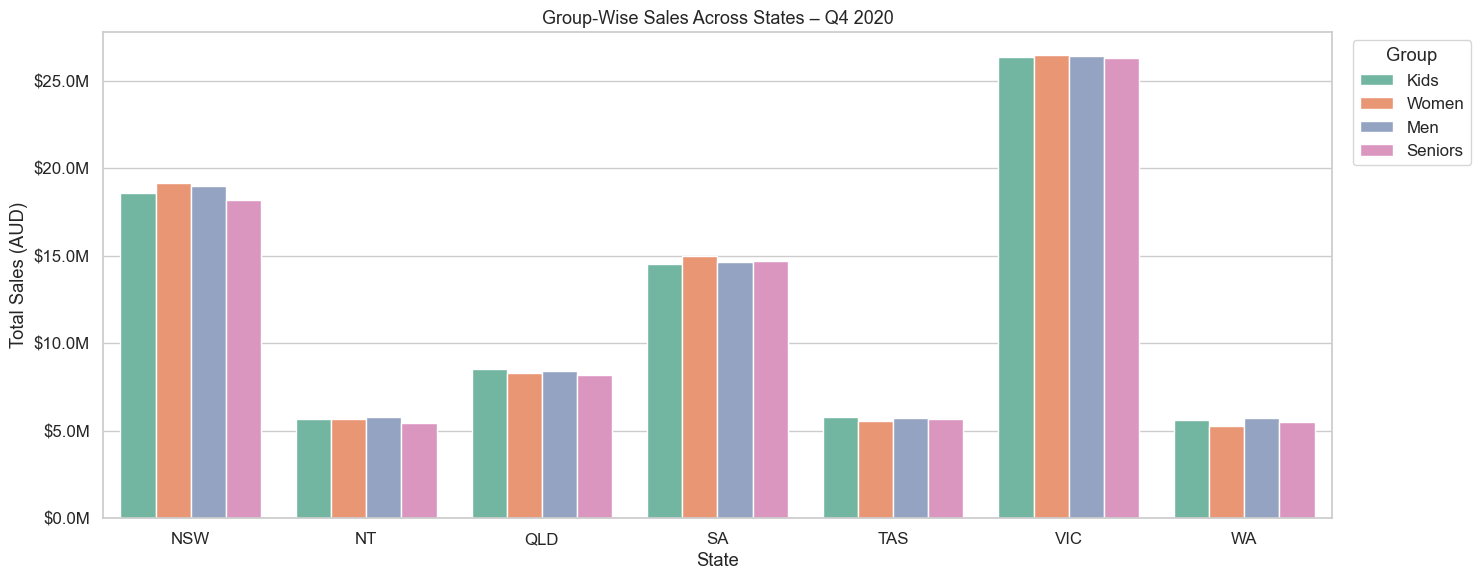

In [24]:
# Grouped bar chart – states on x-axis, group as hue
fig, ax = plt.subplots(figsize=(15, 6))
sns.barplot(
    data=state_group, x='State', y='Sales', hue='Group',
    hue_order=group_order, palette='Set2', ax=ax
)
ax.set_title('Group-Wise Sales Across States – Q4 2020', fontsize=13)
ax.set_xlabel('State')
ax.set_ylabel('Total Sales (AUD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax.legend(title='Group', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig('fig_groupwise_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.5 Time-of-Day Analysis – Peak vs Off-Peak

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/1555907754.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=time_sales, x='Time', y='Sales', order=time_order,
/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/1555907754.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=time_units, x='Time', y='Unit', order=time_order,


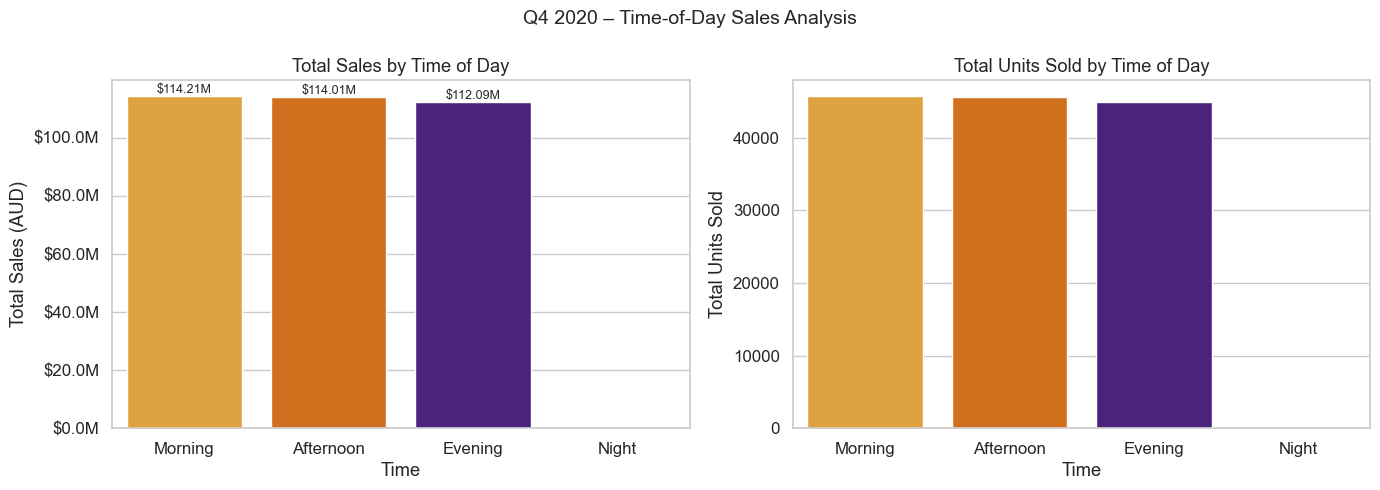

In [25]:
time_sales = df.groupby('Time', observed=True)['Sales'].sum().reset_index()
time_units = df.groupby('Time', observed=True)['Unit'].sum().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

palette_tod = {'Morning': '#F9A825', 'Afternoon': '#EF6C00', 'Evening': '#4A148C', 'Night': '#0D47A1'}

sns.barplot(data=time_sales, x='Time', y='Sales', order=time_order,
            palette=[palette_tod[t] for t in time_order], ax=axes[0])
axes[0].set_title('Total Sales by Time of Day')
axes[0].set_ylabel('Total Sales (AUD)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.01,
                 f'${bar.get_height()/1e6:.2f}M', ha='center', fontsize=9)

sns.barplot(data=time_units, x='Time', y='Unit', order=time_order,
            palette=[palette_tod[t] for t in time_order], ax=axes[1])
axes[1].set_title('Total Units Sold by Time of Day')
axes[1].set_ylabel('Total Units Sold')

plt.suptitle('Q4 2020 – Time-of-Day Sales Analysis', fontsize=14)
plt.tight_layout()
plt.savefig('fig_time_of_day.png', dpi=150, bbox_inches='tight')
plt.show()

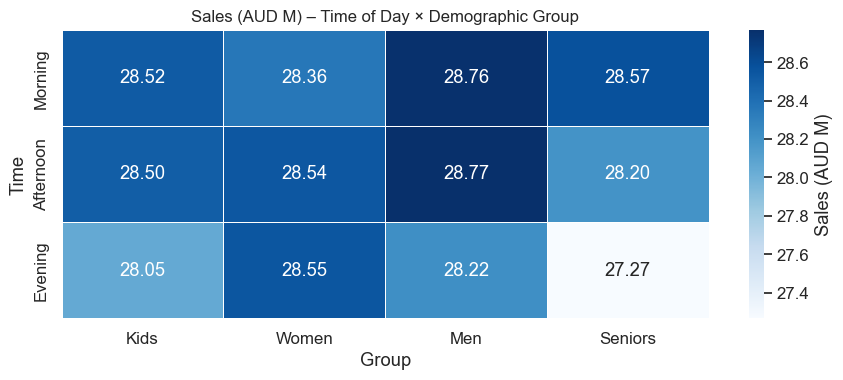

In [26]:
# Time-of-Day × Group heatmap
tod_group = df.pivot_table(
    values='Sales', index='Time', columns='Group',
    aggfunc='sum', observed=True
)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(tod_group/1e6, annot=True, fmt='.2f', cmap='Blues',
            linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Sales (AUD M)'})
ax.set_title('Sales (AUD M) – Time of Day × Demographic Group', fontsize=12)
plt.tight_layout()
plt.savefig('fig_tod_group_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.6 Daily Sales Trend

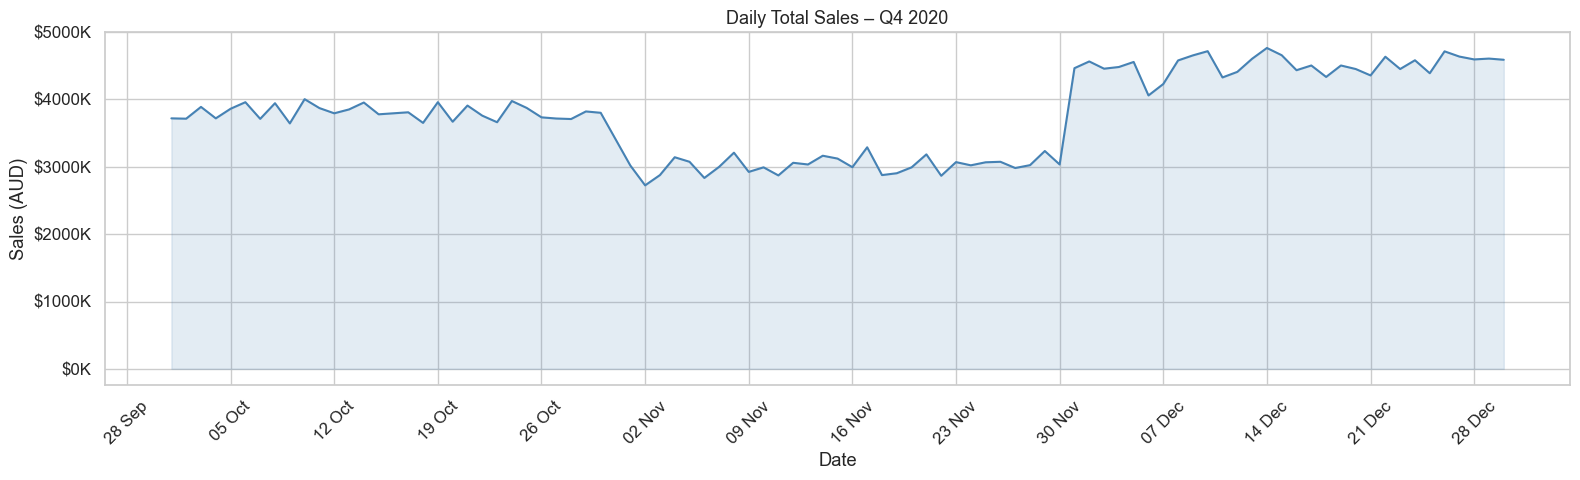

In [27]:
daily = df.groupby('Date')['Sales'].sum().reset_index()

fig, ax = plt.subplots(figsize=(16, 5))
sns.lineplot(data=daily, x='Date', y='Sales', ax=ax, color='steelblue', linewidth=1.5)
ax.fill_between(daily['Date'], daily['Sales'], alpha=0.15, color='steelblue')
ax.set_title('Daily Total Sales – Q4 2020', fontsize=13)
ax.set_xlabel('Date')
ax.set_ylabel('Sales (AUD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))
ax.xaxis.set_major_locator(plt.matplotlib.dates.WeekdayLocator(byweekday=0))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d %b'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fig_daily_trend.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.7 Weekly Sales Trend

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/273752181.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=weekly_trend, x='Week', y='Sales', palette='viridis', ax=ax)


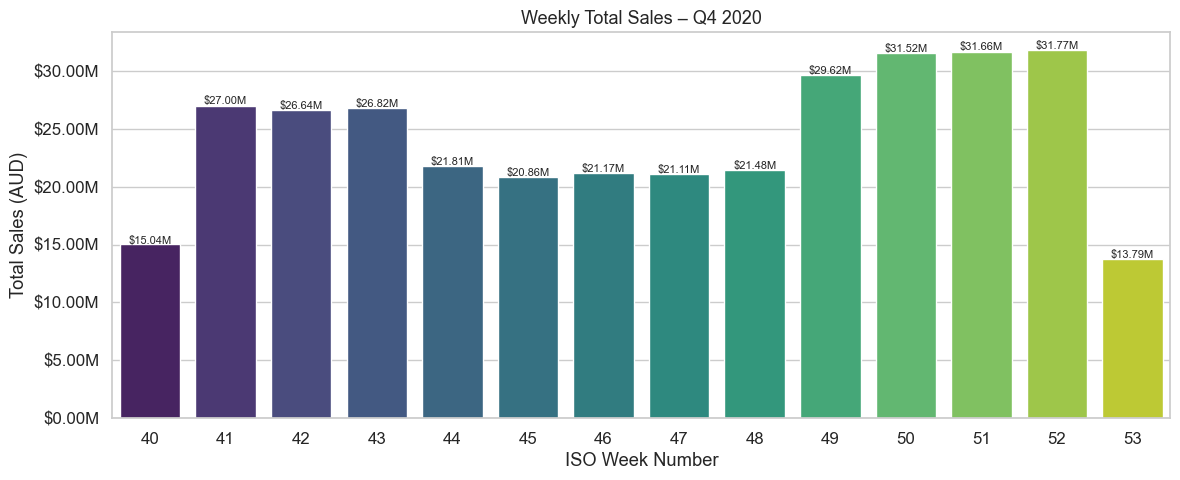

In [28]:
weekly_trend = df.groupby('Week')['Sales'].sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=weekly_trend, x='Week', y='Sales', palette='viridis', ax=ax)
ax.set_title('Weekly Total Sales – Q4 2020', fontsize=13)
ax.set_xlabel('ISO Week Number')
ax.set_ylabel('Total Sales (AUD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.2f}M'))
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.005,
            f'${bar.get_height()/1e6:.2f}M', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('fig_weekly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.8 Monthly Sales Trend

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/3374905562.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly_trend, x='Month_Name', y='Sales',


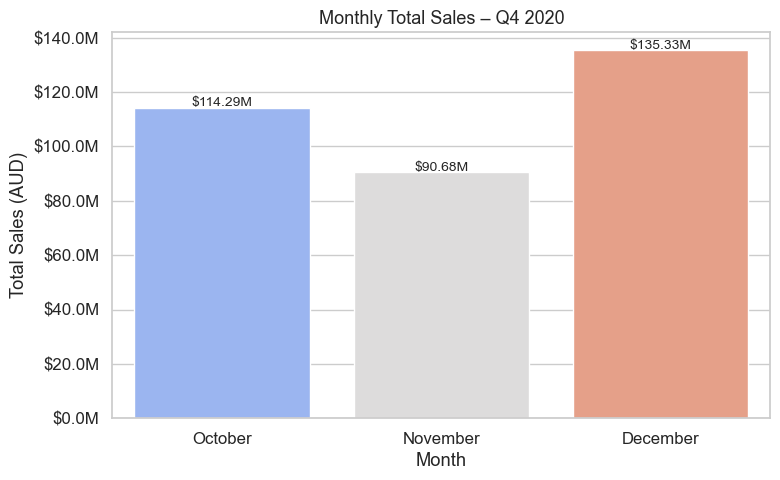

In [29]:
monthly_trend = df.groupby('Month_Name', observed=True)['Sales'].sum().reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=monthly_trend, x='Month_Name', y='Sales',
            order=month_order, palette='coolwarm', ax=ax)
ax.set_title('Monthly Total Sales – Q4 2020', fontsize=13)
ax.set_xlabel('Month')
ax.set_ylabel('Total Sales (AUD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.005,
            f'${bar.get_height()/1e6:.2f}M', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('fig_monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.9 State-Level Total Sales – Rankings

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/3324289480.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(data=state_rank, x='State', y='Sales', palette='RdYlGn_r', ax=ax)


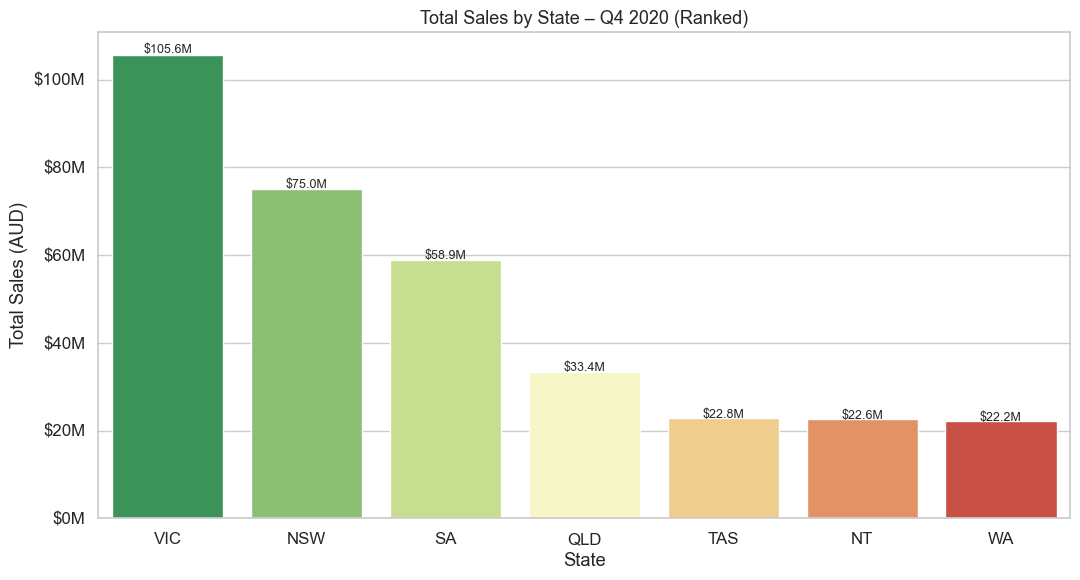

In [30]:
state_rank = df.groupby('State')['Sales'].sum().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(11, 6))
bars = sns.barplot(data=state_rank, x='State', y='Sales', palette='RdYlGn_r', ax=ax)
ax.set_title('Total Sales by State – Q4 2020 (Ranked)', fontsize=13)
ax.set_xlabel('State')
ax.set_ylabel('Total Sales (AUD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.005,
            f'${bar.get_height()/1e6:.1f}M', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('fig_state_ranking.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.10 Quarterly Dashboard – Summary Panel

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/4001921552.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_rank_d, x='State', y='Sales', palette='RdYlGn_r', ax=ax1)
/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/4001921552.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=grp_d, x='Group', y='Sales', order=group_order, palette='Set2', ax=ax2)
/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/4001921552.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tod_d, x='

/var/folders/pd/3_2qgcyn5s77fwf4m2v5jkxh0000gn/T/ipykernel_47586/4001921552.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=mon_d, x='Month_Name', y='Sales', order=month_order, palette='coolwarm', ax=ax5)


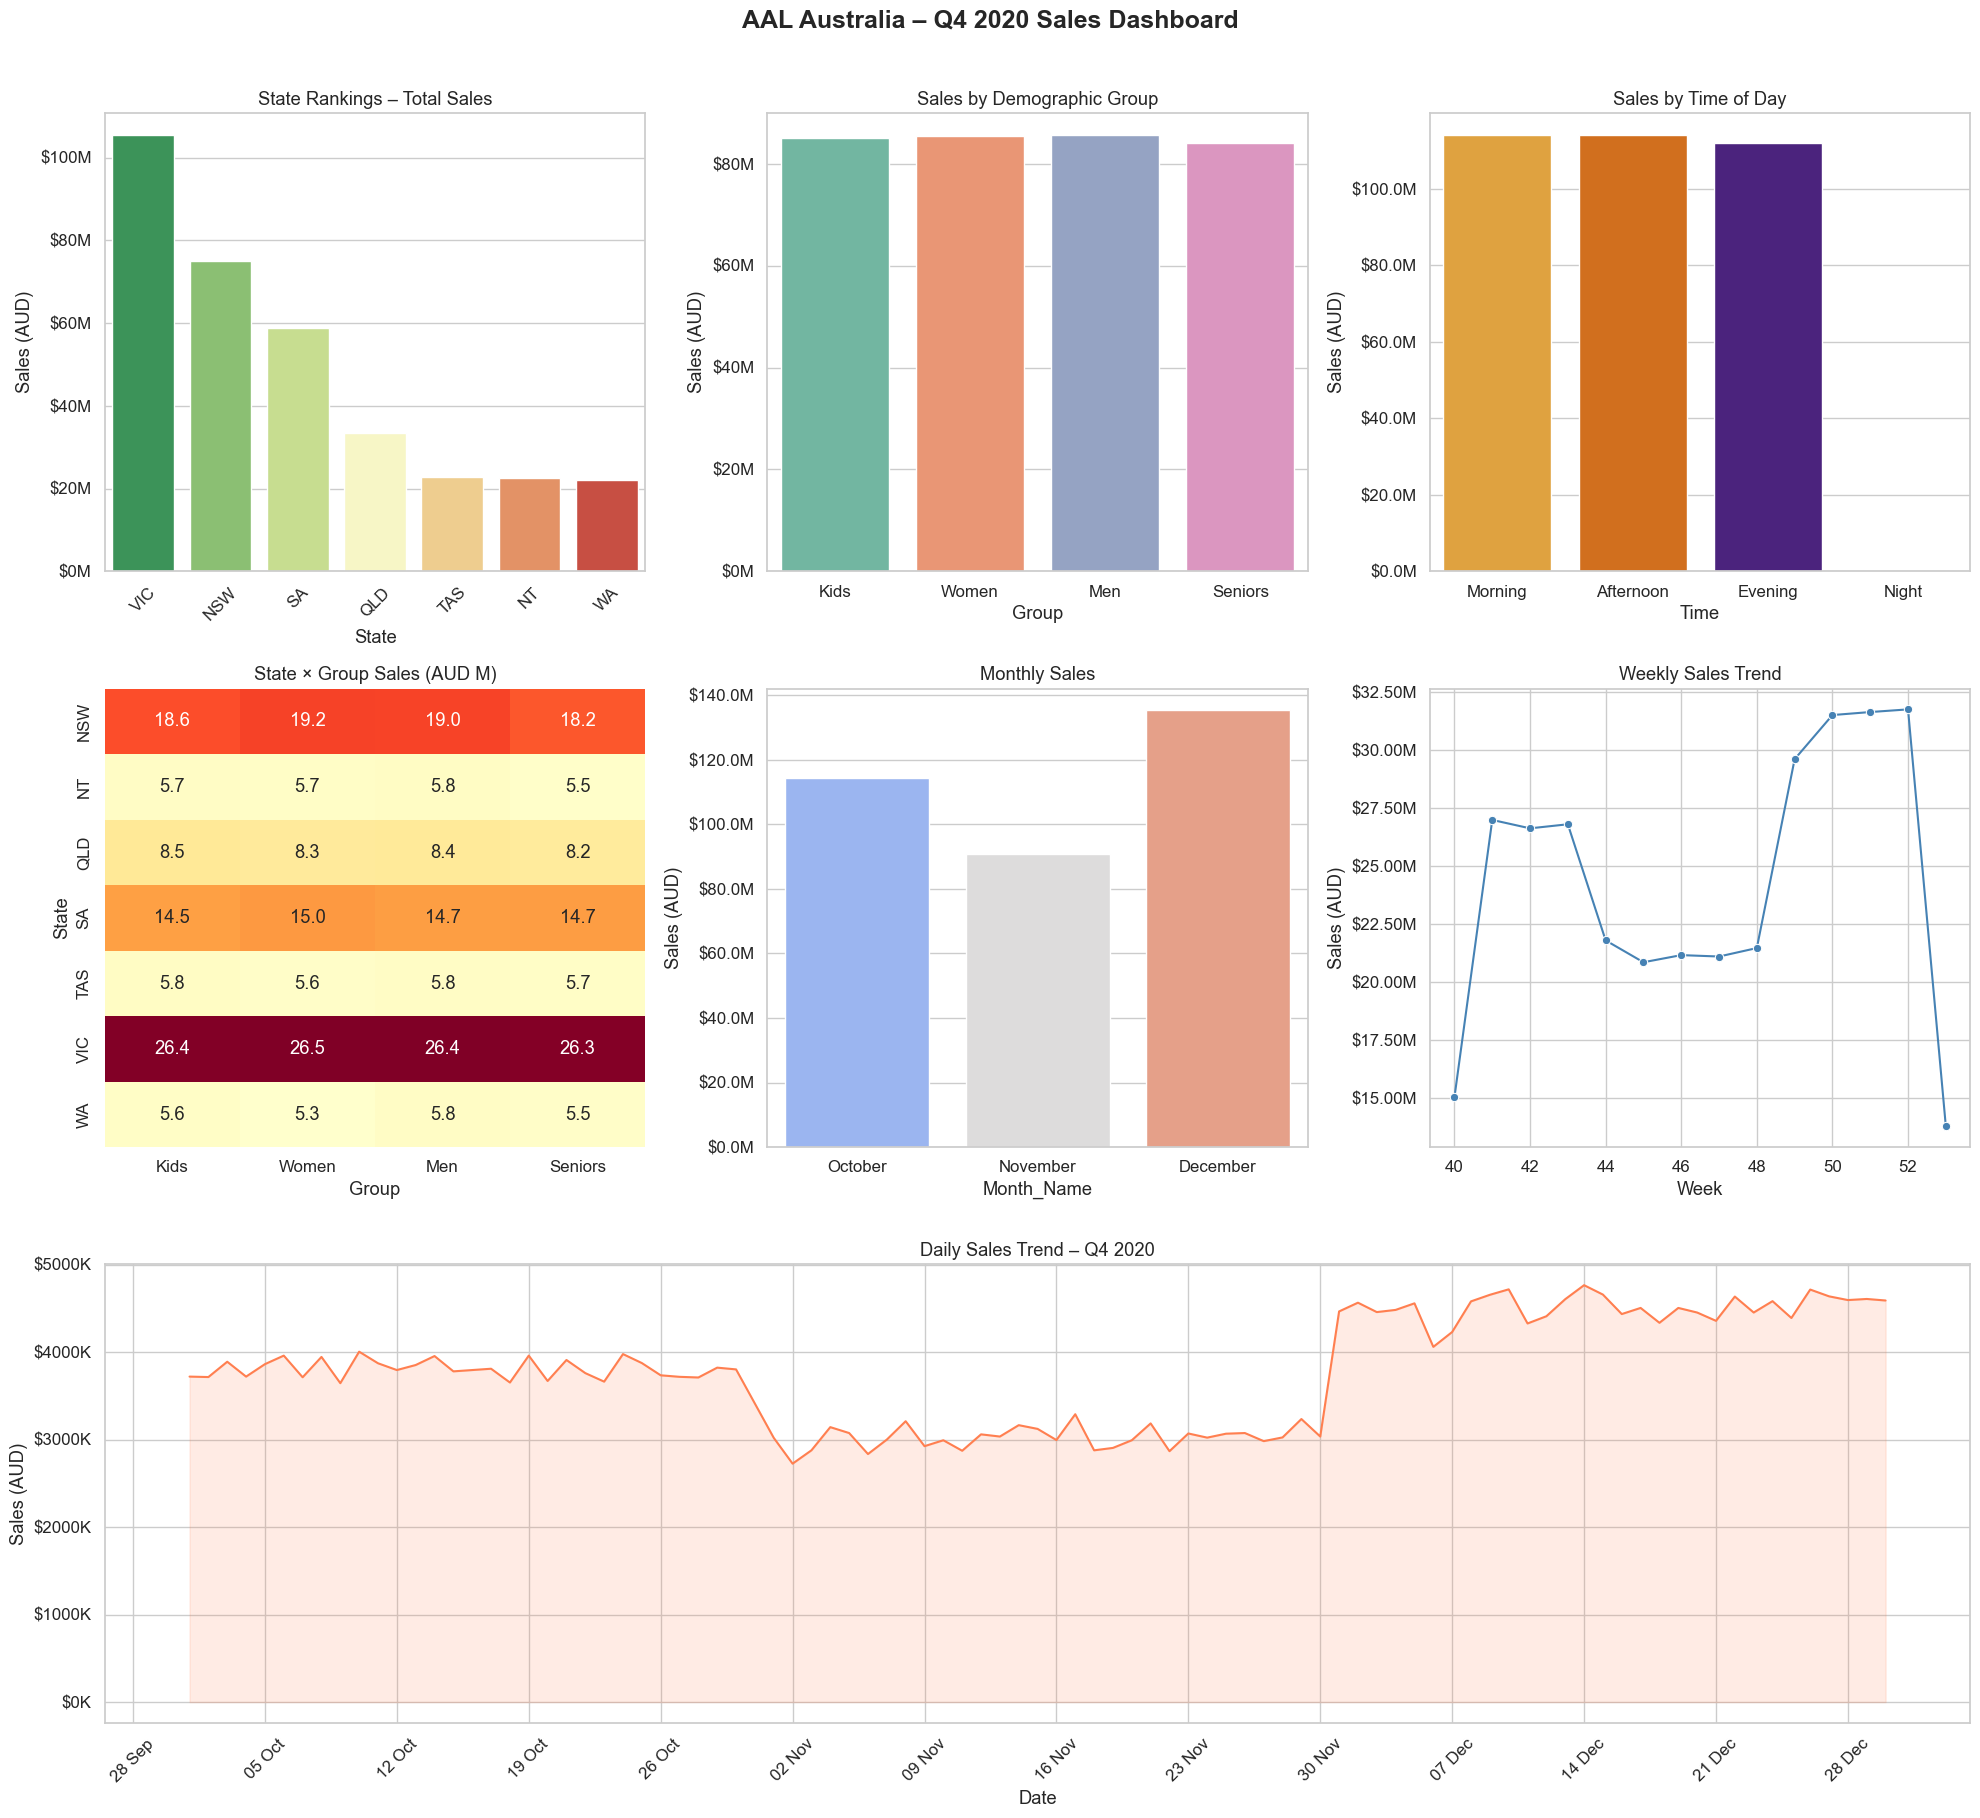

Dashboard saved as fig_dashboard.png


In [31]:
fig = plt.figure(figsize=(20, 18))
fig.suptitle('AAL Australia – Q4 2020 Sales Dashboard', fontsize=18, y=1.01, fontweight='bold')

# (A) State ranking 
ax1 = fig.add_subplot(3, 3, 1)
state_rank_d = df.groupby('State')['Sales'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=state_rank_d, x='State', y='Sales', palette='RdYlGn_r', ax=ax1)
ax1.set_title('State Rankings – Total Sales')
ax1.set_ylabel('Sales (AUD)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))
ax1.tick_params(axis='x', rotation=45)

# (B) Group totals 
ax2 = fig.add_subplot(3, 3, 2)
grp_d = df.groupby('Group', observed=True)['Sales'].sum().reset_index()
sns.barplot(data=grp_d, x='Group', y='Sales', order=group_order, palette='Set2', ax=ax2)
ax2.set_title('Sales by Demographic Group')
ax2.set_ylabel('Sales (AUD)')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))

# (C) Time of day 
ax3 = fig.add_subplot(3, 3, 3)
tod_d = df.groupby('Time', observed=True)['Sales'].sum().reset_index()
palette_tod2 = ['#F9A825','#EF6C00','#4A148C','#0D47A1']
sns.barplot(data=tod_d, x='Time', y='Sales', order=time_order, palette=palette_tod2, ax=ax3)
ax3.set_title('Sales by Time of Day')
ax3.set_ylabel('Sales (AUD)')
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

# (D) Heatmap state × group 
ax4 = fig.add_subplot(3, 3, 4)
piv_d = df.pivot_table('Sales','State','Group',aggfunc='sum',observed=True)/1e6
sns.heatmap(piv_d, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax4, cbar=False)
ax4.set_title('State × Group Sales (AUD M)')

# (E) Monthly trend
ax5 = fig.add_subplot(3, 3, 5)
mon_d = df.groupby('Month_Name', observed=True)['Sales'].sum().reset_index()
sns.barplot(data=mon_d, x='Month_Name', y='Sales', order=month_order, palette='coolwarm', ax=ax5)
ax5.set_title('Monthly Sales')
ax5.set_ylabel('Sales (AUD)')
ax5.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

#  (F) Weekly trend 
ax6 = fig.add_subplot(3, 3, 6)
wkl_d = df.groupby('Week')['Sales'].sum().reset_index()
sns.lineplot(data=wkl_d, x='Week', y='Sales', marker='o', ax=ax6, color='steelblue')
ax6.set_title('Weekly Sales Trend')
ax6.set_ylabel('Sales (AUD)')
ax6.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.2f}M'))

#  (G) Daily trend 
ax7 = fig.add_subplot(3, 1, 3)
day_d = df.groupby('Date')['Sales'].sum().reset_index()
sns.lineplot(data=day_d, x='Date', y='Sales', ax=ax7, color='coral', linewidth=1.5)
ax7.fill_between(day_d['Date'], day_d['Sales'], alpha=0.15, color='coral')
ax7.set_title('Daily Sales Trend – Q4 2020')
ax7.set_xlabel('Date')
ax7.set_ylabel('Sales (AUD)')
ax7.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))
ax7.xaxis.set_major_locator(plt.matplotlib.dates.WeekdayLocator(byweekday=0))
ax7.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d %b'))
plt.setp(ax7.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.savefig('fig_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Dashboard saved as fig_dashboard.png')

---
## 5. Key Findings & Recommendations

*(Populate cells below after running analysis – values will be computed live from the data.)*

In [32]:
top3_states  = state_rank.head(3)['State'].tolist()
bot3_states  = state_rank.tail(3)['State'].tolist()
top_group    = group_sales.idxmax()
bot_group    = group_sales.idxmin()
peak_time    = df.groupby('Time', observed=True)['Sales'].sum().idxmax()
offpeak_time = df.groupby('Time', observed=True)['Sales'].sum().idxmin()

print('=== FINAL INSIGHTS ===')
print(f'Top revenue states   : {", ".join(top3_states)}')
print(f'Low revenue states   : {", ".join(bot3_states)} → target for sales programs')
print(f'Highest-sales group  : {top_group}')
print(f'Lowest-sales group   : {bot_group}')
print(f'Peak period          : {peak_time} → schedule promotions & hyper-personalisation here')
print(f'Off-peak period      : {offpeak_time} → opportunity for Next Best Offer campaigns')

=== FINAL INSIGHTS ===
Top revenue states   : VIC, NSW, SA
Low revenue states   : TAS, NT, WA → target for sales programs
Highest-sales group  : Men
Lowest-sales group   : Seniors
Peak period          : Morning → schedule promotions & hyper-personalisation here
Off-peak period      : Evening → opportunity for Next Best Offer campaigns
